# Kết quả mới sau tuần 10 — NUCLE

**Cách đọc:** xem biểu đồ → đọc nhận xét → mở bảng chi tiết khi cần. Checkpoint là toàn bộ **report TUẦN 10.docx**, bao gồm phần BERT ba seed ở cuối báo cáo. Không lặp lại validation, sensitivity hoặc audit 18 ca đã có ở mốc đó.

| Phần mới | Bằng chứng trình bày |
|---|---|
| Khóa mô hình và ablation Full−P/M | 4 cấu hình bổ sung; test của toàn bộ variant |
| Đánh giá test | Benchmark, từng lớp, confusion, các lát cắt |
| Độ tin cậy và đóng góp feature | Paired group-bootstrap, CI hiệu số |
| Audit test | 40 ca, ví dụ và giới hạn mới |
| Chẩn đoán BERT trên train | Gradient, marker, target pair, học thuộc |
| Kiểm chứng | Raw-to-test replay và kiểm số học |

Chỉ đọc kết quả đã lưu; không huấn luyện/chấm test mới. **BERT chưa có test.** Chạy từ thư mục gốc hoặc notebooks với numpy, pandas, matplotlib, IPython. Bảng/hình đã được lưu trong notebook để xem ngoại tuyến.


In [1]:
from pathlib import Path
import json, hashlib, io, html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML, Image
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'reports/final_evaluation/test_metrics.json').exists()), None)
assert ROOT is not None, 'Mở notebook trong repository NUCLE.'
sources = {}
def path(rel):
    p = ROOT/rel
    sources[rel] = hashlib.sha256(p.read_bytes()).hexdigest()
    return p
def js(rel): return json.loads(path(rel).read_text(encoding='utf-8-sig'))
def csv(rel): return pd.read_csv(path(rel))
def table(df, title=None):
    content = df.to_html(index=False, float_format=lambda x: f'{x:.4f}', na_rep='N/A', border=0)
    if title: content = f'<details><summary><b>{html.escape(title)} ({len(df)} dòng)</b></summary>{content}</details>'
    display(HTML(content))
def figure(fig):
    fig.tight_layout()
    out = io.BytesIO(); fig.savefig(out, format='png', dpi=130, bbox_inches='tight')
    plt.close(fig); display(Image(data=out.getvalue()))
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':10, 'axes.spines.top':False, 'axes.spines.right':False})
colors = ['#94a3b8', '#e9a23b', '#167d9a', '#7564a7']
metrics = js('reports/final_evaluation/test_metrics.json')
overall = csv('reports/evaluation_followup/reviewed_overall_results.csv')
selection = js('reports/final_evaluation/selection_summary.json')
diff = csv('reports/final_evaluation/paired_differences.csv')
main_ids = ['Majority', 'POS', 'LR_03', 'Tree_03']
names = {'Majority':'Majority', 'POS':'POS rule', 'LR_03':'LR Full', 'Tree_03':'Tree Full'}
labels = metrics['all']['label_order']


## 1. Kết quả test chính: LR Full mạnh nhất trong bốn mô hình tham chiếu

**2.368 mẫu · 144 essays · 97 groups · 5 lớp.** Cấu hình chọn bằng validation, khóa trước test; model fit train, không refit train+validation. CI95% từ 1.000 paired group-bootstrap, không đo biến thiên giữa seed training.


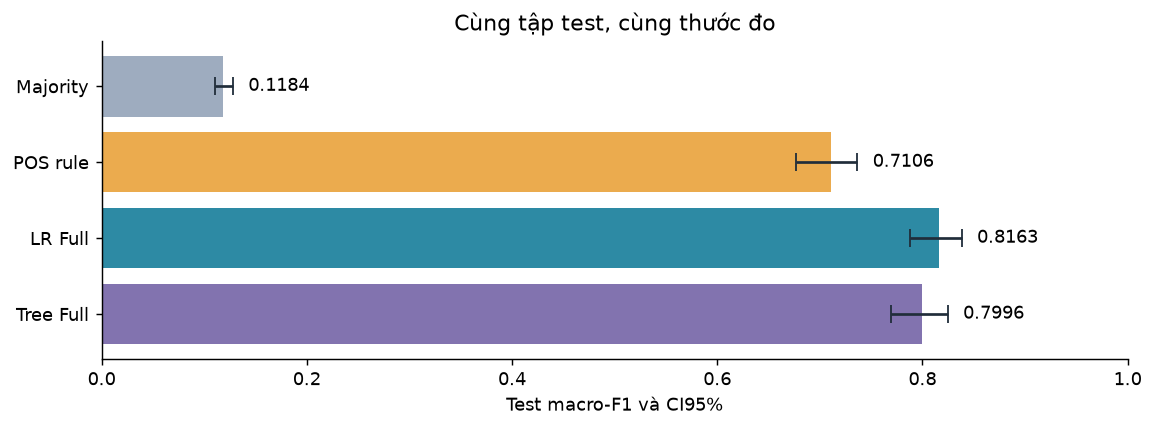

name,test_macro_f1,accuracy,macro_precision,macro_recall,ci95_low,ci95_high
Majority,0.1184,0.4206,0.0841,0.2000,0.1104,0.1279
POS rule,0.7106,0.7441,0.7387,0.7184,0.6766,0.7365
LR S+L+P+M+D,0.8163,0.8357,0.8271,0.8073,0.7876,0.8382
Tree S+L+P+M+D,0.7996,0.8095,0.8064,0.7937,0.7693,0.8246


pipeline,name,test_macro_f1,accuracy,macro_precision,macro_recall,ci95_low,ci95_high,alias_of
Majority,Majority,0.1184,0.4206,0.0841,0.2000,0.1104,0.1279,—
POS,POS rule,0.7106,0.7441,0.7387,0.7184,0.6766,0.7365,—
LR_00,LR S+L,0.7203,0.7753,0.7514,0.7013,0.6875,0.7467,—
Tree_00,Tree S+L,0.5850,0.6520,0.6431,0.5594,0.5601,0.6052,—
LR_01,LR S+L+P,0.7968,0.8269,0.8066,0.7885,0.7659,0.8195,—
Tree_01,Tree S+L+P,0.7520,0.7893,0.7692,0.7396,0.7193,0.7774,—
LR_02,LR S+L+P+M,0.8102,0.8328,0.8188,0.8028,0.7775,0.8349,—
Tree_02,Tree S+L+P+M,0.7967,0.8121,0.8087,0.7868,0.7674,0.8201,—
LR_03,LR S+L+P+M+D,0.8163,0.8357,0.8271,0.8073,0.7876,0.8382,—
Tree_03,Tree S+L+P+M+D,0.7996,0.8095,0.8064,0.7937,0.7693,0.8246,—


In [2]:
main = overall.set_index('pipeline').loc[main_ids].reset_index()
fig, ax = plt.subplots(figsize=(9, 3.4))
y = np.arange(4); score = main.test_macro_f1.to_numpy()
ax.barh(y, score, color=colors, alpha=.9)
ax.errorbar(score, y, xerr=np.vstack([score-main.ci95_low, main.ci95_high-score]), fmt='none', ecolor='#202d3a', capsize=5)
for i,v in enumerate(score): ax.text(main.ci95_high.iloc[i]+.015, i, f'{v:.4f}', va='center')
ax.set(yticks=y, yticklabels=[names[x] for x in main_ids], xlim=(0,1), xlabel='Test macro-F1 và CI95%', title='Cùng tập test, cùng thước đo'); ax.invert_yaxis()
figure(fig)
table(main[['name','test_macro_f1','accuracy','macro_precision','macro_recall','ci95_low','ci95_high']])
table(overall.drop(columns='validation_macro_f1').fillna({'alias_of':'—'}), 'Mở toàn bộ 20 pipeline test, gồm alias')


**Đọc kết quả:** LR Full F1≈0,8163 so với POS≈0,7106; accuracy≈0,8357. Majority accuracy≈0,4206 nhưng F1≈0,1184 cho thấy accuracy đơn lẻ che khuất thất bại ở lớp nhỏ. Hai tên Full−D là alias, không phải thí nghiệm độc lập. Không dùng bảng test để chọn lại mô hình.

## 2. Mô hình mạnh/yếu ở lớp nào?
Heatmap so POS, LR Full và Tree Full; confusion tập trung LR Full. Hàng là gold, cột là prediction, số trong ô là số mẫu.


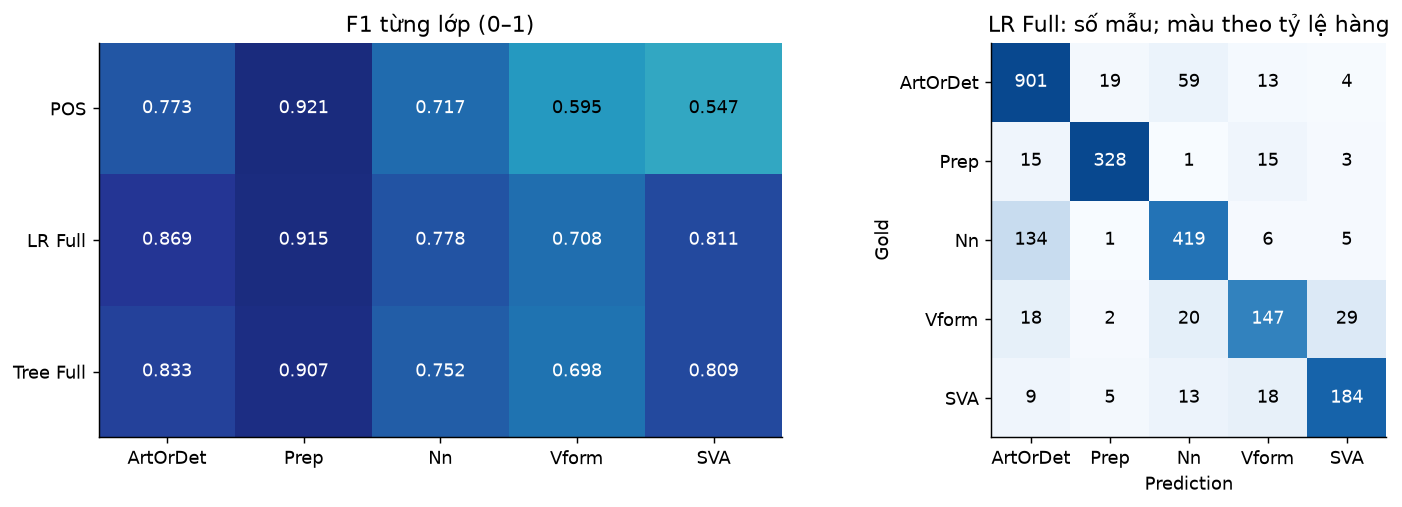

label,precision,recall,f1,support
ArtOrDet,0.8366,0.9046,0.8693,996
Prep,0.9239,0.9061,0.9149,362
Nn,0.8184,0.7416,0.7781,565
Vform,0.7387,0.6806,0.7084,216
SVA,0.8178,0.8035,0.8106,229


pipeline,label,precision,recall,f1,support
Majority,ArtOrDet,0.4206,1.0000,0.5922,996
Majority,Prep,0.0000,0.0000,0.0000,362
Majority,Nn,0.0000,0.0000,0.0000,565
Majority,Vform,0.0000,0.0000,0.0000,216
Majority,SVA,0.0000,0.0000,0.0000,229
POS,ArtOrDet,0.8390,0.7169,0.7731,996
POS,Prep,0.9224,0.9199,0.9212,362
POS,Nn,0.6352,0.8230,0.7170,565
POS,Vform,0.5099,0.7130,0.5946,216
POS,SVA,0.7869,0.4192,0.5470,229


In [3]:
per_class = csv('reports/final_evaluation/per_class_results.csv')
f1 = per_class.pivot(index='pipeline', columns='label', values='f1').loc[['POS','LR_03','Tree_03'], labels]
cm = np.asarray(metrics['all']['models']['LR_03']['confusion'])
norm = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].imshow(f1, vmin=0, vmax=1, cmap='YlGnBu', aspect='auto')
axes[0].set(xticks=range(5), xticklabels=labels, yticks=range(3), yticklabels=['POS','LR Full','Tree Full'], title='F1 từng lớp (0–1)')
for i in range(3):
    for j in range(5): axes[0].text(j,i,f'{f1.iloc[i,j]:.3f}',ha='center',va='center',color='white' if f1.iloc[i,j]>.65 else 'black')
axes[1].imshow(norm, vmin=0, vmax=1, cmap='Blues')
axes[1].set(xticks=range(5),xticklabels=labels,yticks=range(5),yticklabels=labels,xlabel='Prediction',ylabel='Gold',title='LR Full: số mẫu; màu theo tỷ lệ hàng')
for i in range(5):
    for j in range(5): axes[1].text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if norm[i,j]>.55 else 'black')
figure(fig)
table(per_class.loc[per_class.pipeline.eq('LR_03'), ['label','precision','recall','f1','support']])
table(per_class, 'Mở từng lớp của toàn bộ mô hình')


**Điểm cần giải thích:** LR nhầm Nn→ArtOrDet 134 ca, chiều ngược 59; Vform→SVA 29, chiều ngược 18. Đây là mẫu nhầm quan sát được, chưa chứng minh nguyên nhân do parser hoặc nhãn.

## 3. Các nhóm khó: span và cặp nhãn cùng POS
Hiển thị sáu slice liên quan câu hỏi nghiên cứu, không chọn theo điểm cao. Các slice chồng lấp nên không cộng support. Span dùng F1 năm lớp; pair/POS dùng F1 hai nhãn trong cặp, prediction ngoài cặp vẫn tính lỗi.


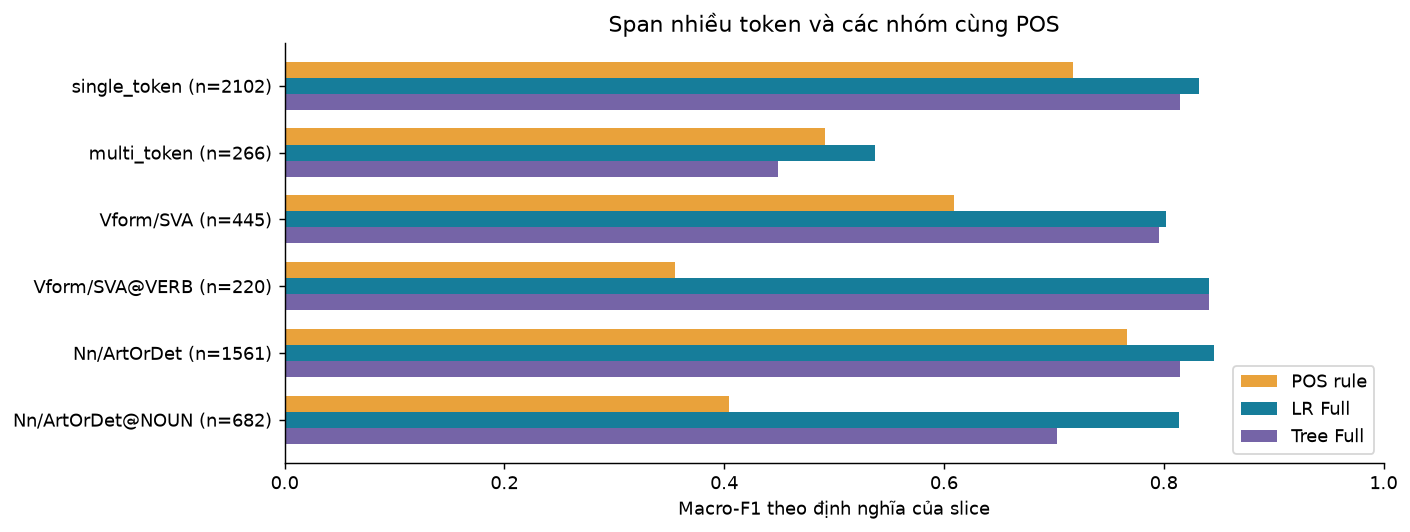

pipeline,slice,support,LR_03,POS,Tree_03
,Nn/ArtOrDet,1561,0.8453,0.7663,0.8148
,Nn/ArtOrDet@AUX,3,0.0000,0.0000,0.0000
,Nn/ArtOrDet@DET,343,0.4827,0.4827,0.4827
,Nn/ArtOrDet@NOUN,682,0.8142,0.4044,0.7028
,Nn/ArtOrDet@VERB,33,0.3864,0.0000,0.4843
,Vform/SVA,445,0.8021,0.6095,0.7959
,Vform/SVA@AUX,105,0.8477,0.4670,0.8677
,Vform/SVA@DET,1,0.0000,0.0000,0.0000
,Vform/SVA@NOUN,37,0.1667,0.0000,0.1071
,Vform/SVA@VERB,220,0.8416,0.3548,0.8412


slice,pipeline,support,macro_f1,accuracy
all,Majority,2368,0.1184,0.4206
all,POS,2368,0.7106,0.7441
all,LR_00,2368,0.7203,0.7753
all,Tree_00,2368,0.5850,0.6520
all,LR_01,2368,0.7968,0.8269
all,Tree_01,2368,0.7520,0.7893
all,LR_02,2368,0.8102,0.8328
all,Tree_02,2368,0.7967,0.8121
all,LR_03,2368,0.8163,0.8357
all,Tree_03,2368,0.7996,0.8095


In [4]:
chosen = ['single_token','multi_token','Vform/SVA','Vform/SVA@VERB','Nn/ArtOrDet','Nn/ArtOrDet@NOUN']
fig, ax = plt.subplots(figsize=(11,4.2))
y = np.arange(len(chosen)); width=.24
for j,key in enumerate(['POS','LR_03','Tree_03']):
    ax.barh(y+(j-1)*width, [metrics[s]['models'][key]['macro_f1'] for s in chosen], height=width, label=names[key], color=colors[j+1])
ax.set(yticks=y,yticklabels=[f"{s} (n={metrics[s]['support']})" for s in chosen], xlim=(0,1),xlabel='Macro-F1 theo định nghĩa của slice',title='Span nhiều token và các nhóm cùng POS'); ax.invert_yaxis(); ax.legend(loc='lower right')
figure(fig)
slice_rows=[]; class_rows=[]
for s,g in metrics.items():
    for model,r in g['models'].items():
        slice_rows.append({'slice':s,'pipeline':model,'support':g['support'],'macro_f1':r['macro_f1'],'accuracy':r['accuracy']})
        for label,values in r.get('per_label',{}).items(): class_rows.append({'slice':s,'pipeline':model,'label':label,**values})
slice_frame=pd.DataFrame(slice_rows)
table(slice_frame.loc[slice_frame.pipeline.isin(['POS','LR_03','Tree_03']) & slice_frame['slice'].ne('all')].pivot(index=['slice','support'],columns='pipeline',values='macro_f1').reset_index(), 'Mở tất cả slice của ba mô hình chính, kể cả nhóm nhỏ')
table(slice_frame, 'Tra toàn bộ 280 model–slice')


**Giới hạn:** multi-token có phân bố lớp khác single-token, không quy giảm điểm chỉ cho độ dài. Nhóm rất nhỏ như Vform/SVA@DET chỉ có 1 mẫu và Nn/ArtOrDet@AUX có 3 mẫu không đủ để kết luận mạnh; span rỗng có 0 mẫu, ghi N/A.

## 4. Ablation và CI: thông tin nào thực sự giúp?
Trái: test của các biểu diễn LR/Tree. Phải: hiệu số Full−variant cùng CI95%. Đường 0 giúp thấy phép so nào chưa có bằng chứng tăng ổn định. Các variant tune riêng; bỏ P/M vẫn có thông tin liên quan trong D.


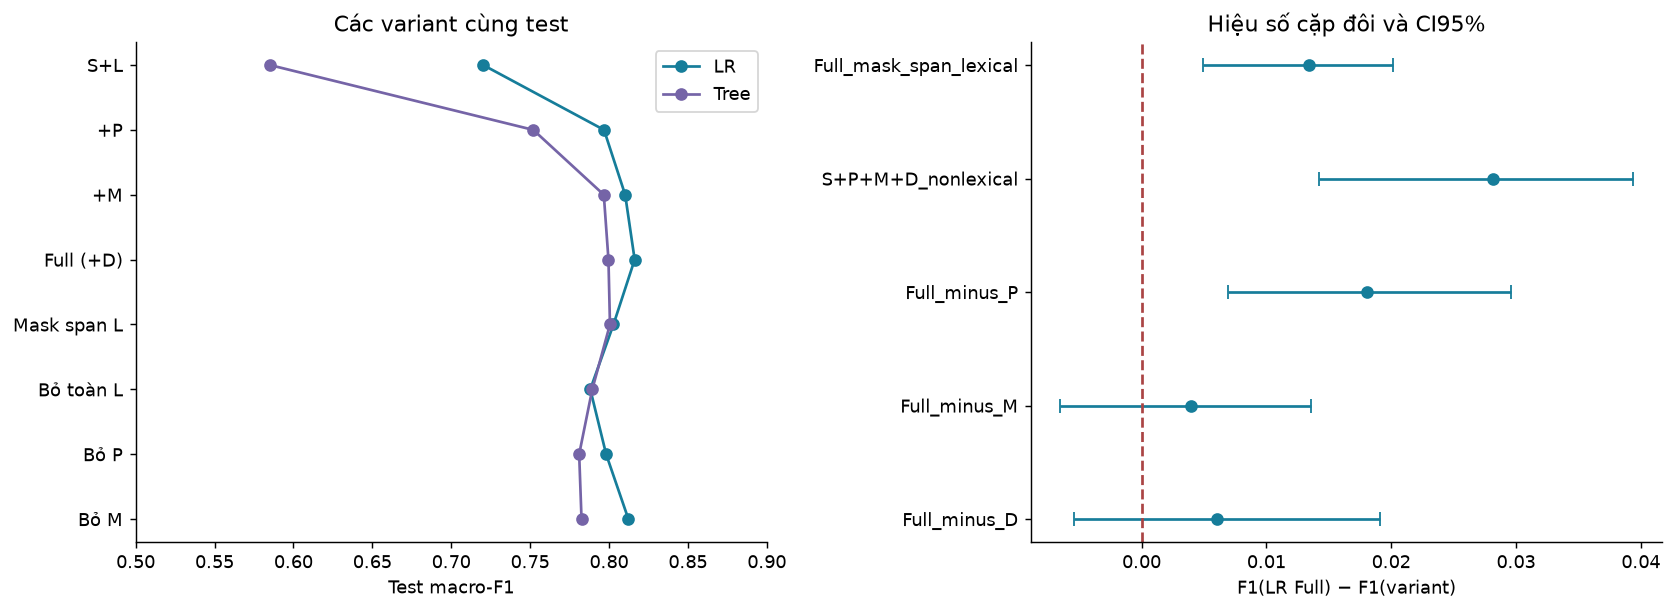

pipeline,name,validation_macro_f1,test_macro_f1
LR_06,LR Full_minus_P,0.8001,0.7982
Tree_06,Tree Full_minus_P,0.7711,0.7811
LR_07,LR Full_minus_M,0.8015,0.8123
Tree_07,Tree Full_minus_M,0.7751,0.7826


contrast,difference,ci95_low,ci95_high
LR Full - Tree Full,0.0166,0.0018,0.0301
LR Full - POS,0.1057,0.0829,0.1288


slice,contrast,a,b,difference,ci95,valid_replicates,ci95_low,ci95_high
all,LR Full - Majority,LR_03,Majority,0.6978,"[0.6655228394256505, 0.7212040465322135]",1000,0.6655,0.7212
all,Tree Full - Majority,Tree_03,Majority,0.6812,"[0.6469791257300923, 0.7072728996491933]",1000,0.6470,0.7073
all,LR Full - Tree Full,LR_03,Tree_03,0.0166,"[0.001793044274060257, 0.030060755324963103]",1000,0.0018,0.0301
all,LR Full - POS,LR_03,POS,0.1057,"[0.08291596501680508, 0.12883459009823986]",1000,0.0829,0.1288
all,LR S+L+P minus S+L,LR_01,LR_00,0.0766,"[0.05813763959446661, 0.09745045128215885]",1000,0.0581,0.0975
all,LR S+L+P+M minus S+L+P,LR_02,LR_01,0.0134,"[-0.0004352504669207196, 0.025570386863339397]",1000,-0.0004,0.0256
all,LR S+L+P+M+D minus S+L+P+M,LR_03,LR_02,0.0060,"[-0.005397393414570259, 0.01911307539220087]",1000,-0.0054,0.0191
all,LR S+L+P+M+D minus Full_mask_span_lexical,LR_03,LR_04,0.0134,"[0.004901173718200619, 0.020108111278130635]",1000,0.0049,0.0201
all,LR S+L+P+M+D minus S+P+M+D_nonlexical,LR_03,LR_05,0.0281,"[0.0141878673423666, 0.03940747274257951]",1000,0.0142,0.0394
all,LR S+L+P+M+D minus Full_minus_P,LR_03,LR_06,0.0181,"[0.006949972446998051, 0.02961952472737871]",1000,0.0069,0.0296


id,variant,configuration,feature_count
LR_00,S+L,"{'C': 1.0, 'class_weight': None}",9203
Tree_00,S+L,"{'max_depth': 12, 'min_samples_leaf': 5, 'class_weight': None}",9203
LR_01,S+L+P,"{'C': 1.0, 'class_weight': None}",15271
Tree_01,S+L+P,"{'max_depth': 12, 'min_samples_leaf': 5, 'class_weight': None}",15271
LR_02,S+L+P+M,"{'C': 1.0, 'class_weight': None}",15302
Tree_02,S+L+P+M,"{'max_depth': 12, 'min_samples_leaf': 5, 'class_weight': 'balanced'}",15302
LR_03,S+L+P+M+D,"{'C': 0.1, 'class_weight': None}",16180
Tree_03,S+L+P+M+D,"{'max_depth': 8, 'min_samples_leaf': 5, 'class_weight': None}",16180
LR_04,Full_mask_span_lexical,"{'C': 0.1, 'class_weight': None}",16180
Tree_04,Full_mask_span_lexical,"{'max_depth': 12, 'min_samples_leaf': 5, 'class_weight': 'balanced'}",16180


In [5]:
ov=overall.set_index('pipeline')
variants=['S+L','+P','+M','Full (+D)','Mask span L','Bỏ toàn L','Bỏ P','Bỏ M']
fig,axes=plt.subplots(1,2,figsize=(13,4.8))
for prefix,color in [('LR','#167d9a'),('Tree','#7564a7')]:
    axes[0].plot([ov.loc[f'{prefix}_{i:02d}','test_macro_f1'] for i in range(8)], range(8), 'o-', label=prefix,color=color)
axes[0].set(yticks=range(8),yticklabels=variants,xlim=(.5,.9),xlabel='Test macro-F1',title='Các variant cùng test'); axes[0].invert_yaxis(); axes[0].legend()
contrast=diff.loc[diff['slice'].eq('all') & diff.a.eq('LR_03') & diff.b.isin(['LR_04','LR_05','LR_06','LR_07','LR_08'])].copy()
v=contrast.difference.to_numpy(); y=np.arange(len(v))
axes[1].errorbar(v,y,xerr=np.vstack([v-contrast.ci95_low,contrast.ci95_high-v]),fmt='o',color='#167d9a',capsize=4)
axes[1].axvline(0,color='#a44',linestyle='--'); axes[1].set(yticks=y,yticklabels=[ov.loc[x,'name'].replace('LR ','') for x in contrast.b],xlabel='F1(LR Full) − F1(variant)',title='Hiệu số cặp đôi và CI95%'); axes[1].invert_yaxis()
figure(fig)
new_ids=['LR_06','Tree_06','LR_07','Tree_07']
table(overall.loc[overall.pipeline.isin(new_ids),['pipeline','name','validation_macro_f1','test_macro_f1']], '4 kết quả validation mới Full−P/M và test tương ứng')
table(diff.loc[diff['slice'].eq('all') & diff.a.eq('LR_03') & diff.b.isin(['POS','Tree_03']), ['contrast','difference','ci95_low','ci95_high']])
table(diff, 'Mở toàn bộ CI hiệu số, gồm các slice')
configs=pd.DataFrame([{k:r[k] for k in ['id','variant','configuration','feature_count']} for r in selection['selected']])
table(configs, 'Cấu hình khóa trước test')


**Kết luận:** lexical và POS có bằng chứng hữu ích với LR; CI lợi ích M/D của LR chứa 0. Morphology có bằng chứng rõ hơn ở Tree. CI riêng lẻ chồng lấn không thay thế phép kiểm hiệu số cặp đôi. 40 fit grid mới Full−P/M + 12 refit; Full−D dùng lại S+L+P+M.

## 5. Audit test: lỗi nào còn tồn tại?
40 ca chọn có chủ đích: 25 lỗi LR, 5 lỗi Tree khi LR đúng, 10 ca LR đúng. Review có AI hỗ trợ, không phải chuyên gia độc lập; số lượng từng nhóm dưới đây không đại diện tỷ lệ corpus.


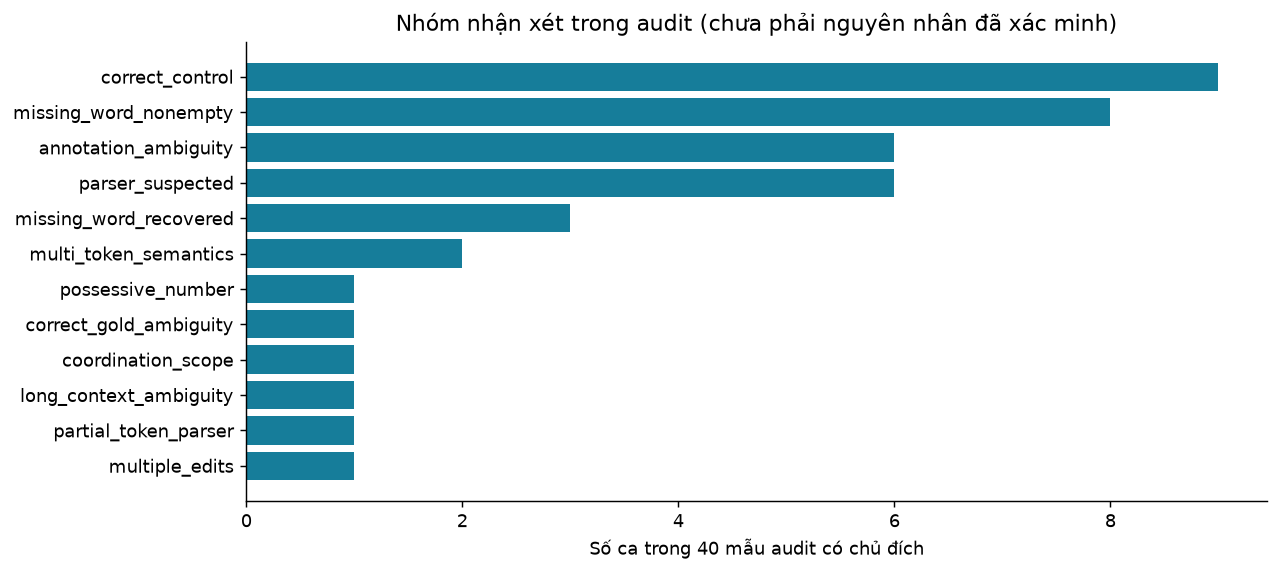

annotation_id,category,explanation
38087,missing_word_nonempty,"Gold ArtOrDet nhưng span nguồn là ADP; edit thêm determiner sau giới từ. Cả ba dự đoán Prep. Đây là thiếu từ được neo vào span không rỗng, không phải lỗi offset."
34539,annotation_ambiguity,Gold ArtOrDet nhưng edit thêm particle cho động từ; khác với mô tả nhãn mạo từ. Cần người chuyên môn xác minh taxonomy/annotation; giữ nguyên gold.
34483,multiple_edits,Gold Nn với span DET+NOUN; correction vừa bỏ determiner vừa đổi danh từ sang số nhiều. Cả ba chọn ArtOrDet; một nhãn bao phủ nhiều thay đổi.
17814,partial_token_parser,Gold Nn trên một ký tự cuối token; tokenizer/POS biểu diễn token bao phủ bằng ADP. Edit thêm dấu số nhiều cho danh từ ghép bị tách. Phân biệt offset hợp lệ với biểu diễn token không phù hợp.


annotation_id,category,confidence,explanation
19312,multi_token_semantics,medium,Span DET+NOUN gồm mạo từ và danh từ không đếm được; edit loại determiner. POS đúng nhưng LR/Tree chọn Nn. Cần phân biệt khả năng đếm với số danh từ; không quy toàn bộ lỗi cho POS.
38087,missing_word_nonempty,high,"Gold ArtOrDet nhưng span nguồn là ADP; edit thêm determiner sau giới từ. Cả ba dự đoán Prep. Đây là thiếu từ được neo vào span không rỗng, không phải lỗi offset."
34539,annotation_ambiguity,medium,Gold ArtOrDet nhưng edit thêm particle cho động từ; khác với mô tả nhãn mạo từ. Cần người chuyên môn xác minh taxonomy/annotation; giữ nguyên gold.
24526,parser_suspected,medium,"Cụm danh từ hai token bị gán NOUN+VERB, token sau có VerbForm=Part. Edit thêm determiner. Tín hiệu verb sai có thể liên quan dự đoán Vform, chưa chứng minh quan hệ nhân quả."
34483,multiple_edits,high,Gold Nn với span DET+NOUN; correction vừa bỏ determiner vừa đổi danh từ sang số nhiều. Cả ba chọn ArtOrDet; một nhãn bao phủ nhiều thay đổi.
17814,partial_token_parser,high,Gold Nn trên một ký tự cuối token; tokenizer/POS biểu diễn token bao phủ bằng ADP. Edit thêm dấu số nhiều cho danh từ ghép bị tách. Phân biệt offset hợp lệ với biểu diễn token không phù hợp.
9351,parser_suspected,medium,"Danh từ chỉ sự trợ giúp bị phân tích thành VERB hữu hạn ngôi ba, có nsubj giả theo cách đọc ngữ cảnh. Edit bỏ số nhiều phù hợp Nn; LR bị hút sang SVA, Tree đúng."
41235,parser_suspected,medium,"Trong vị trí bổ ngữ của động từ, target có nghĩa danh từ nghiên cứu nhưng POS là VERB dù dependency là dobj. Morph sing/finite không phù hợp cách đọc danh từ; cả ba sai."
24747,missing_word_nonempty,high,"Gold Prep nhưng target là DET; correction thêm giới từ trước determiner. Cả ba chọn ArtOrDet theo token neo, không biểu diễn trực tiếp từ thiếu."
17826,missing_word_nonempty,high,Gold Prep nhưng target là NOUN; correction thêm giới từ trước danh từ. Cả ba chọn Nn; cần quan hệ kết hợp động từ–giới từ.


annotation_id,gold,current_category,question,status,expert_decision
34539,ArtOrDet,annotation_ambiguity,Nhãn ArtOrDet có phù hợp với thao tác thêm particle trong annotation này không?,pending_independent_human_review,N/A
12324,SVA,annotation_ambiguity,Nhãn SVA liên quan phần nào của câu khi correction không trực tiếp đổi agreement?,pending_independent_human_review,N/A
26635,SVA,annotation_ambiguity,Correction xóa giới từ nhưng nhãn SVA: cần đọc các annotation liên quan để giải thích.,pending_independent_human_review,N/A
32705,ArtOrDet,annotation_ambiguity,Correction thay giới từ nhưng nhãn ArtOrDet: kiểm taxonomy/annotation gốc.,pending_independent_human_review,N/A
37909,Nn,annotation_ambiguity,Correction xóa determiner nhưng nhãn Nn: đây là convention hay nhãn cần xem lại?,pending_independent_human_review,N/A
18501,ArtOrDet,annotation_ambiguity,Correction đảo auxiliary trong mệnh đề gián tiếp: kiểm cả tính phù hợp của edit và nhãn ArtOrDet.,pending_independent_human_review,N/A
201,Vform,correct_gold_ambiguity,Cấu trúc pseudo-cleft này có bắt buộc thêm dấu infinitive không?,pending_independent_human_review,N/A
18531,SVA,coordination_scope,Động từ thuộc phạm vi phối hợp nào; gold SVA có phù hợp cách đọc toàn câu?,pending_independent_human_review,N/A
37631,Vform,long_context_ambiguity,Phạm vi danh sách/mệnh đề và cách đọc noun/verb có thống nhất với correction không?,pending_independent_human_review,N/A
11916,ArtOrDet,missing_word_recovered,Determiner được thêm có bắt buộc trong ngữ cảnh này hay là lựa chọn diễn đạt?,pending_independent_human_review,N/A


annotation_id,gold,LR,POS,contrast,intercept,margin,scope,contributions_by_group.S,contributions_by_group.L,contributions_by_group.P,contributions_by_group.M,contributions_by_group.D
11916,ArtOrDet,ArtOrDet,Nn,logit(ArtOrDet) - logit(Nn),0.1070,0.9541,Post-hoc algebraic explanation of saved logits; not causal feature importance or new evaluation,-0.0525,0.5895,0.0763,0.3155,-0.0818
44353,ArtOrDet,ArtOrDet,Nn,logit(ArtOrDet) - logit(Nn),0.1070,0.7514,Post-hoc algebraic explanation of saved logits; not causal feature importance or new evaluation,-0.1783,0.5032,0.8217,0.3155,-0.8177
6079,ArtOrDet,ArtOrDet,Nn,logit(ArtOrDet) - logit(Nn),0.1070,1.0470,Post-hoc algebraic explanation of saved logits; not causal feature importance or new evaluation,-0.0422,1.6728,-0.8141,0.3155,-0.1921
44388,ArtOrDet,Nn,Nn,logit(ArtOrDet) - logit(Nn),0.1070,-0.0808,Post-hoc algebraic explanation of saved logits; not causal feature importance or new evaluation,-0.0865,0.2885,0.1125,0.3155,-0.8177


In [6]:
audit=js('reports/final_evaluation/manual_error_review.json')
followup=js('reports/evaluation_followup/audit_followup.json')
notes=pd.DataFrame(audit['notes'])
counts=notes.category.value_counts().sort_values()
fig,ax=plt.subplots(figsize=(10,4.5)); ax.barh(counts.index,counts.values,color='#167d9a'); ax.set(xlabel='Số ca trong 40 mẫu audit có chủ đích',title='Nhóm nhận xét trong audit (chưa phải nguyên nhân đã xác minh)'); figure(fig)
# Bốn ví dụ cố định đại diện bốn vấn đề; không chọn theo model đúng.
examples=['38087','17814','34483','34539']
table(notes.loc[notes.annotation_id.astype(str).isin(examples),['annotation_id','category','explanation']])
table(notes, 'Mở tất cả 40 ghi chú audit ban đầu')
table(csv('reports/evaluation_followup/expert_review_queue.csv'), '17 ca chờ chuyên gia; gold giữ nguyên')
margin=pd.json_normalize(followup['lr_margin_decompositions'])
table(margin, '4 phân rã logit mới: giải thích đại số, không phải nhân quả')


**Phát hiện mới:** 16/40 ca có edit chỉ thêm từ trong span không rỗng; ID 26635/37909 có correction rỗng thật (xóa). Extractor chỉ lấy subject child trực tiếp nên có thể bỏ subject gắn ở head của auxiliary. Các nhận định parser/gold cần đọc cùng [review sau audit](../reports/evaluation_followup/review_report.md); không tự kết luận 17 annotation sai.

## 6. BERT: có học được không? — chẩn đoán mới trên train
Không lặp lại validation ba seed của tuần 10. Gradient, marker, cặp target cùng câu và học thuộc kiểm tra các khía cạnh khác nhau; không phải điểm test hoặc bằng chứng tổng quát hóa.


Kiểm tra,Bằng chứng,Giới hạn
Gradient/optimizer,"4 probe; kiểm CE, coverage, gradient và update",Không xác nhận mô hình tổng quát hóa
"Dời marker, CLS",28/100 prediction đổi,Phản ứng với marker chưa chứng minh định vị đúng
Hai target cùng câu,7/50 cặp đổi prediction; 2 cặp đúng cả hai,"Stress test trên train, chọn có chủ đích"


run,updates,accuracy,CE,passed
cls_lr_5e-05,400,1.0000,0.1515,False
cls_lr_0.001,100,1.0000,0.0073,True
span_mean_lr_0.001,75,1.0000,0.0104,True


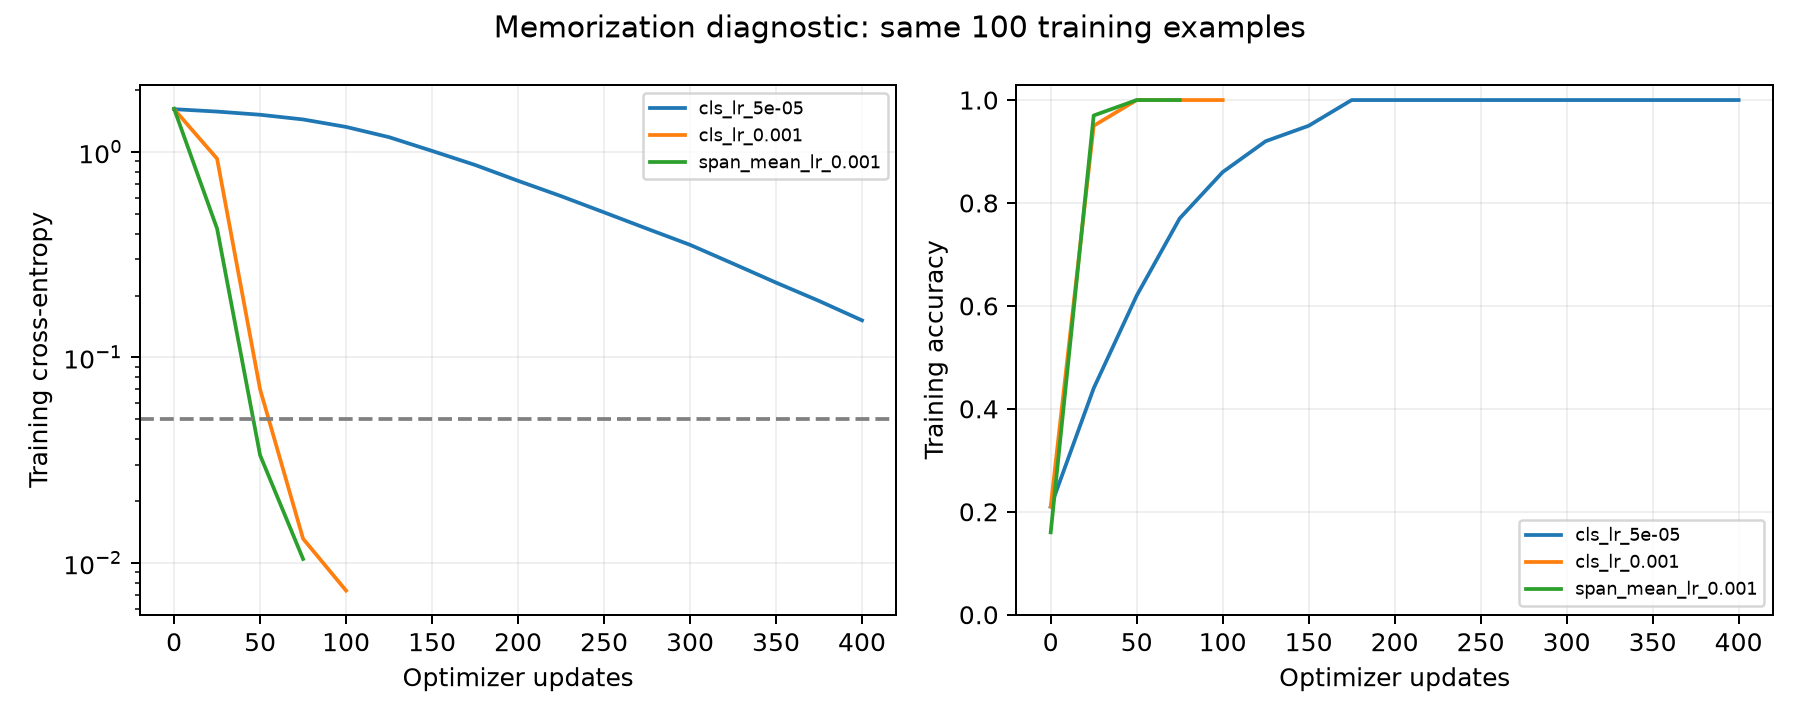

probe,mode,loss,manual_ce_abs_difference,original_cls_logits_max_difference,optimizer_covers_all_trainable_parameters,missing_gradients,nonfinite_gradients,target_embedding_gradient_norm,hidden_gradients,global_gradient_norm_before_clip,gradient_norms.embeddings,gradient_norms.encoder.layer.0,gradient_norms.encoder.layer.1,gradient_norms.pooler,gradient_norms.classifier,marker_embedding_gradients.30522,marker_embedding_gradients.30523,parameter_update_norms.start_marker,parameter_update_norms.end_marker,parameter_update_norms.encoder_query,parameter_update_norms.classifier
pretrained_cls,cls,1.6034,0.0000,0.0000,True,[],[],0.0708,"[{'layer_output': 0, 'cls_gradient_norm': 0.009183835238218307, 'target_gradient_norm': 0.0027311407029628754, 'marker_gradient_norm': 0.00479305861517787}, {'layer_output': 1, 'cls_gradient_norm': 0.025611404329538345, 'target_gradient_norm': 0.002451011911034584, 'marker_gradient_norm': 0.0014508848544210196}, {'layer_output': 2, 'cls_gradient_norm': 0.017070576548576355, 'target_gradient_norm': 0.0, 'marker_gradient_norm': 0.0}]",0.9383,0.6546,0.3074,0.2350,0.1979,0.5128,0.0659,0.0591,0.0006,0.0006,0.0064,0.0013
pretrained_span_mean,span_mean,1.6194,0.0000,N/A,True,[],[],0.1564,"[{'layer_output': 0, 'cls_gradient_norm': 0.0053740330040454865, 'target_gradient_norm': 0.010319296270608902, 'marker_gradient_norm': 0.0111443642526865}, {'layer_output': 1, 'cls_gradient_norm': 0.015945760533213615, 'target_gradient_norm': 0.01891058310866356, 'marker_gradient_norm': 0.016368968412280083}, {'layer_output': 2, 'cls_gradient_norm': 0.0, 'target_gradient_norm': 0.019268622621893883, 'marker_gradient_norm': 0.0}]",1.4068,0.8658,0.5759,0.3520,0.2574,0.8412,0.2430,0.1734,0.0006,0.0006,0.0064,0.0013
saved_failed_run_cls,cls,1.7080,0.0000,0.0000,True,[],[],0.0388,"[{'layer_output': 0, 'cls_gradient_norm': 0.019436564296483994, 'target_gradient_norm': 0.012514784932136536, 'marker_gradient_norm': 0.029529402032494545}, {'layer_output': 1, 'cls_gradient_norm': 0.05248091369867325, 'target_gradient_norm': 0.011642045341432095, 'marker_gradient_norm': 0.012084413319826126}, {'layer_output': 2, 'cls_gradient_norm': 0.03341555967926979, 'target_gradient_norm': 0.0, 'marker_gradient_norm': 0.0}]",7.1320,6.0747,2.4794,1.6808,0.4756,2.1827,1.2230,0.8118,0.0006,0.0006,0.0064,0.0013
saved_failed_run_span_mean,span_mean,1.6800,0.0000,N/A,True,[],[],0.0791,"[{'layer_output': 0, 'cls_gradient_norm': 0.010015989653766155, 'target_gradient_norm': 0.018160181120038033, 'marker_gradient_norm': 0.02760464698076248}, {'layer_output': 1, 'cls_gradient_norm': 0.024791914969682693, 'target_gradient_norm': 0.0338967889547348, 'marker_gradient_norm': 0.025528455153107643}, {'layer_output': 2, 'cls_gradient_norm': 0.0, 'target_gradient_norm': 0.02918754145503044, 'marker_gradient_norm': 0.0}]",4.8334,3.9371,1.6333,1.1071,0.4702,1.9356,1.0850,0.6920,0.0006,0.0006,0.0064,0.0013


sentence_sha256,sample_ids,gold,prediction,predictions_differ,both_correct,cls_cosine,span_mean_cosine
54a762439f94726f1ca3e728760d16112080b2a13e46c986318bbe5eff6fdeb2,"[8441a60060730bdc6af1e79a064c68441ecb24a66da91ea2aab0061a64a130ac:36252, 8441a60060730bdc6af1e79a064c68441ecb24a66da91ea2aab0061a64a130ac:36254]","[Prep, Vform]","[ArtOrDet, ArtOrDet]",False,False,0.9005,0.7278
9f93ce21745fad0294c60c0e27fa0fd7c194df96698a6a52886fcbcc5856d0f9,"[8441a60060730bdc6af1e79a064c68441ecb24a66da91ea2aab0061a64a130ac:14304, 8441a60060730bdc6af1e79a064c68441ecb24a66da91ea2aab0061a64a130ac:14305]","[SVA, ArtOrDet]","[ArtOrDet, ArtOrDet]",False,False,0.9650,0.7337
af1c58119cb19e078ec152476471bddfafc065ce16803e3f4c26f4bc4b4f543f,"[8441a60060730bdc6af1e79a064c68441ecb24a66da91ea2aab0061a64a130ac:8648, 8441a60060730bdc6af1e79a064c68441ecb24a66da91ea2aab0061a64a130ac:8649]","[ArtOrDet, Nn]","[ArtOrDet, ArtOrDet]",False,False,0.9977,0.7428
ec2572af7a7d7e69f2a9edef46c34fd216ad6fde1930b54f117a52c6980513dc,"[8441a60060730bdc6af1e79a064c68441ecb24a66da91ea2aab0061a64a130ac:36408, 8441a60060730bdc6af1e79a064c68441ecb24a66da91ea2aab0061a64a130ac:36410]","[ArtOrDet, SVA]","[ArtOrDet, ArtOrDet]",False,False,0.9866,0.7523
ba8672b47ada420559c298922246bb5ce673507e6d3a5bb0c4fdfc295c4df64b,"[8441a60060730bdc6af1e79a064c68441ecb24a66da91ea2aab0061a64a130ac:16629, 8441a60060730bdc6af1e79a064c68441ecb24a66da91ea2aab0061a64a130ac:16630]","[SVA, ArtOrDet]","[Nn, Nn]",False,False,0.8957,0.7066
8c5274f1acaa800e9a6241c32fa5b9d3787ca02c42c679aab65e1c91ba6f8ca4,"[8441a60060730bdc6af1e79a064c68441ecb24a66da91ea2aab0061a64a130ac:33239, 8441a60060730bdc6af1e79a064c68441ecb24a66da91ea2aab0061a64a130ac:33243]","[Prep, Vform]","[ArtOrDet, ArtOrDet]",False,False,0.9875,0.6907
2d0c6388385b8b00b4098fff814037eec5d07d492f4d36454ae2ce4317e1d1bc,"[8441a60060730bdc6af1e79a064c68441ecb24a66da91ea2aab0061a64a130ac:5112, 8441a60060730bdc6af1e79a064c68441ecb24a66da91ea2aab0061a64a130ac:5113]","[SVA, Nn]","[ArtOrDet, ArtOrDet]",False,False,0.9897,0.7910
ff643452a2b40b96428ecefe07843e1ec955485594c40b2c089cb8d1b15e7f3e,"[8441a60060730bdc6af1e79a064c68441ecb24a66da91ea2aab0061a64a130ac:7441, 8441a60060730bdc6af1e79a064c68441ecb24a66da91ea2aab0061a64a130ac:7442]","[Nn, SVA]","[Nn, Nn]",False,False,0.9800,0.7816
f1ca1d7f5d2327d023baa08a7dc7aff7d595cb72b3c3b8c9d2e5cafdf6d2e5a1,"[8441a60060730bdc6af1e79a064c68441ecb24a66da91ea2aab0061a64a130ac:7146, 8441a60060730bdc6af1e79a064c68441ecb24a66da91ea2aab0061a64a130ac:7147]","[ArtOrDet, Prep]","[ArtOrDet, ArtOrDet]",False,False,0.9971,0.5588
3a5edb2552e3ecbb845bcf30944f90bf7b82ba84e39a9316c71741d96bd6e7f7,"[8441a60060730bdc6af1e79a064c68441ecb24a66da91ea2aab0061a64a130ac:24097, 8441a60060730bdc6af1e79a064c68441ecb24a66da91ea2aab0061a64a130ac:24098]","[ArtOrDet, SVA]","[ArtOrDet, ArtOrDet]",False,False,0.9341,0.7715


In [7]:
grad=js('reports/bert_learning_diagnostics/gradient_checks.json')
marker=js('reports/bert_learning_diagnostics/marker_sensitivity.json')
pairs=js('reports/bert_learning_diagnostics/same_sentence_pairs.json')
diagnostics=js('reports/bert_learning_diagnostics/summary.json')
table(pd.DataFrame([
 {'Kiểm tra':'Gradient/optimizer','Bằng chứng':f"{len(grad)} probe; kiểm CE, coverage, gradient và update",'Giới hạn':'Không xác nhận mô hình tổng quát hóa'},
 {'Kiểm tra':'Dời marker, CLS','Bằng chứng':f"{marker['cls']['prediction_changes']}/{marker['cls']['examples']} prediction đổi",'Giới hạn':'Phản ứng với marker chưa chứng minh định vị đúng'},
 {'Kiểm tra':'Hai target cùng câu','Bằng chứng':f"{pairs['predictions_differ']}/{pairs['selected_pairs']} cặp đổi prediction; {pairs['both_correct']} cặp đúng cả hai",'Giới hạn':'Stress test trên train, chọn có chủ đích'}]))
runs=pd.DataFrame([{'run':r['name'],'updates':r['updates'],'accuracy':r['metrics']['accuracy'],'CE':r['metrics']['cross_entropy'],'passed':r['memorization_passed']} for r in diagnostics['runs']])
table(runs)
display(Image(filename=str(path('reports/bert_learning_diagnostics/memorization_curves.png'))))
table(pd.json_normalize([{'probe':k,**v} for k,v in grad.items()]), 'Mở chi tiết gradient và optimizer')
table(pd.DataFrame(pairs['rows']), 'Mở 50 cặp target cùng câu')


**Diễn giải:** CLS 5e−5 đạt accuracy 100% nhưng CE≈0,1515 chưa đạt tiêu chí ≤0,05; CLS 1e−3 và span_mean 1e−3 đạt tiêu chí. Recipe tập nhỏ thay nhiều yếu tố, chưa quy thất bại cũ riêng cho learning rate. Gradient target layer cuối bằng 0 với CLS là đặc điểm readout, không tự chứng minh đứt đường học.

## 7. Bằng chứng có tái lập được không?
Các kết quả kiểm chứng dưới đây đã được lưu từ đợt trước. Chạy notebook chỉ kiểm số liệu tổng hợp; không chạy lại 52 fit. Replay trên cùng test không tạo thêm dữ liệu xác nhận độc lập.


In [8]:
evidence=js('reports/evaluation_followup/evidence_review.json')
reproduction=js('reports/evaluation_followup/pipeline_reproduction.json')
table(pd.DataFrame([
 {'Hạng mục':'Pipeline','Kết quả':'SGML → preparation → groups → features → 52 fit → test replay'},
 {'Hạng mục':'Dự đoán test','Kết quả':f"{evidence['pipelines']} pipeline × {evidence['test_rows']} mẫu"},
 {'Hạng mục':'Metric độc lập','Kết quả':f"{evidence['model_slice_metric_checks']} kiểm tra model–slice"},
 {'Hạng mục':'CI độc lập','Kết quả':f"{evidence['model_slice_ci_checks']} CI F1 + {evidence['paired_contrast_ci_checks']} CI hiệu số"},
 {'Hạng mục':'Phạm vi chưa tái lập','Kết quả':'; '.join(reproduction['not_reproduced'])}]))
table(pd.DataFrame([{'stage':k,'evidence':json.dumps(v,ensure_ascii=False)} for k,v in reproduction['stages'].items()]), 'Mở bằng chứng từng bước replay')
for row in overall.itertuples():
    a=np.asarray(metrics['all']['models'][row.pipeline]['confusion'],dtype=float); den=a.sum(0)+a.sum(1)
    f1=np.divide(2*a.diagonal(),den,out=np.zeros_like(den),where=den!=0).mean()
    assert abs(f1-row.test_macro_f1)<1e-12 and abs(a.trace()/a.sum()-row.accuracy)<1e-12
assert len(notes)==40 and len(overall)==20
print('PASS: macro-F1 và accuracy của toàn bộ 20 pipeline khớp confusion matrices; đủ 40 ca audit.')
table(pd.DataFrame([{'source':k,'sha256':v} for k,v in sources.items()]), 'Nguồn dữ liệu và SHA256')


Hạng mục,Kết quả
Pipeline,SGML → preparation → groups → features → 52 fit → test replay
Dự đoán test,20 pipeline × 2368 mẫu
Metric độc lập,280 kiểm tra model–slice
CI độc lập,40 CI F1 + 30 CI hiệu số
Phạm vi chưa tái lập,Independent human annotation adjudication; Historical six-variant grid search; BERT experiments


stage,evidence
source_and_audit,"{""annotations"": 44912, ""essays"": 1397, ""csv_comparison"": {""status"": ""match"", ""expected_rows"": 44912, ""actual_rows"": 44912, ""missing_columns"": [], ""extra_columns"": [], ""column_order_matches"": true, ""different_cells"": 0}, ""audit"": {""sha256"": ""72c80329d5e176905090cb13fc32d702e7e7fd3e2f44c528b420048602276a05"", ""byte_identical"": true}, ""duplicate_report_semantically_identical"": true, ""review_log_sha256"": ""407dcd6657b369f97adb96436cb2dd0b31f3f8c698fb4e012ce4c6002cfefc78""}"
preparation_v2,"{""data_outputs"": {""boundary_challenges.jsonl"": {""sha256"": ""33231698c307daa27b9b33c6aa91d662588803e66b462adee3456d9556a077f0"", ""byte_identical"": true}, ""input_groups.jsonl"": {""sha256"": ""e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855"", ""byte_identical"": true}, ""provenance.jsonl"": {""sha256"": ""d0d2a599ba28b70dcf9ecb80308e2efbb30c0c1cbc089fd9db9a6bf8ab7f63f8"", ""byte_identical"": true}, ""rejected.jsonl"": {""sha256"": ""e690574b29d6b90ce1034527799bbdf8db6dc63c7cab4a171d297ceb16e6bc42"", ""byte_identical"": true}, ""samples.jsonl"": {""sha256"": ""34dfe5375601a671e8312c04e1142899a9c1a25ccf9bd73ec052d77ac8cf9587"", ""byte_identical"": true}, ""sentences.jsonl"": {""sha256"": ""d3fddfa40bdba6e6de74325954429a5586929c6f45a2440a4e8877a8d20aa32e"", ""byte_identical"": true}, ""summary.json"": {""sha256"": ""48260e9f46e1f56c18d73ed33be560d195d12fbeaff5dc69f110f9945828b1be"", ""byte_identical"": true}}, ""manifest_differs_as_expected"": ""New time, code inventory and local input paths; source/data outputs compared directly""}"
group_split,"{""samples"": 15788, ""split_manifest"": {""sha256"": ""c3a65115ad93c837372e1c72d186b244043b711ee41a6706b13ccacea8be5677"", ""byte_identical"": true}, ""essay_groups"": {""sha256"": ""4c623961cefe0eb6cadc37f5a5399b71d2dbb9ef90573b434827b0d60a4efcb2"", ""byte_identical"": true}, ""partitions"": {""train"": {""samples"": 11052, ""fraction"": 0.7000253356979985, ""essays"": 1069, ""groups"": 1045, ""label_counts"": {""ArtOrDet"": 4648, ""Prep"": 1689, ""Nn"": 2638, ""Vform"": 1011, ""SVA"": 1066}}, ""validation"": {""samples"": 2368, ""fraction"": 0.14998733215100077, ""essays"": 142, ""groups"": 99, ""label_counts"": {""ArtOrDet"": 996, ""Prep"": 362, ""Nn"": 565, ""Vform"": 216, ""SVA"": 229}}, ""test"": {""samples"": 2368, ""fraction"": 0.14998733215100077, ""essays"": 144, ""groups"": 97, ""label_counts"": {""ArtOrDet"": 996, ""Prep"": 362, ""Nn"": 565, ""Vform"": 216, ""SVA"": 229}}}}"
features,"{""samples"": 15788, ""dimensions"": 16180, ""sentences_parsed"": 11272, ""files"": {""features.jsonl"": {""sha256"": ""f9a94270b161a7e8ee29da23e2ebd4f4e20a5313005f59b2c4e36ccb6e74ba8b"", ""byte_identical"": true}, ""targets.jsonl"": {""sha256"": ""427bb842b2c99ab0c576e46ca5a807da0647346d2529cd9d28a60a1b4857882b"", ""byte_identical"": true}, ""encoder.json"": {""sha256"": ""d8987f6964ffcd428f7ae3d9ce6c8912dbd12ac4daeff24422e0899967350c27"", ""byte_identical"": true}}}"
training,"{""fits"": 52, ""new_grid"": 40, ""historical_refits"": 12, ""validation_predictions"": {""sha256"": ""ffbed512738c30cd328c59a02dae778944df410b8e82f1d82d054b669861bd81"", ""byte_identical"": true}, ""all_fit_metrics_and_termination_identical"": true, ""selected"": {""LR_00"": {""selected_config_and_validation_identical"": true, ""checkpoint_content_identical"": true}, ""Tree_00"": {""selected_config_and_validation_identical"": true, ""checkpoint_content_identical"": true}, ""LR_01"": {""selected_config_and_validation_identical"": true, ""checkpoint_content_identical"": true}, ""Tree_01"": {""selected_config_and_validation_identical"": true, ""checkpoint_content_identical"": true}, ""LR_02"": {""selected_config_and_validation_identical"": true, ""checkpoint_content_identical"": true}, ""Tree_02"": {""selected_config_and_validation_identical"": true, ""checkpoint_content_identical"": true}, ""LR_03"": {""selected_config_and_validation_identical"": tru

PASS: macro-F1 và accuracy của toàn bộ 20 pipeline khớp confusion matrices; đủ 40 ca audit.


source,sha256
reports/final_evaluation/test_metrics.json,71b73fa90e54e47d973a2fa2342ffcfd24960279352439387d8f3ffcf7b78c55
reports/evaluation_followup/reviewed_overall_results.csv,a081cdc5169a0a7fb900f8589b184182e26c9ea35112f3218a8a42558d075907
reports/final_evaluation/selection_summary.json,707b6a055717158d66729a89b26e441b222a599b1545c879a404caa6f801bce7
reports/final_evaluation/paired_differences.csv,6754064f4193b7b1d1a1b676c78d06cb5dcd5daf460d93e04a15fc920f216be1
reports/final_evaluation/per_class_results.csv,c8629d83489ed06a4b47d0ad0b8831f8b4e8667c9f3df394ce431d45bfe1ef4d
reports/final_evaluation/manual_error_review.json,79785245cb3ba59cc468ec0c19b31c42449393c74b07b818c31302db0d2792e0
reports/evaluation_followup/audit_followup.json,e3b47cc4eae4f24bd404b3c0b20c4a6c9a566539e1f6962da0670276cd5428f0
reports/evaluation_followup/expert_review_queue.csv,66ce82ddfbe41d2e2098ada76e70e2523992365bc9d8c464bcf9e1dc5e1ce44d
reports/bert_learning_diagnostics/gradient_checks.json,b9134194845fa10b765bf09d09b30c4faa2ac376b67c193ea3263cdf4a668d11
reports/bert_learning_diagnostics/marker_sensitivity.json,e74cefd7d8a8a86fbdd9e80a7af808b35b561fad9ebb0352affd5d4c472698a3


## Kết luận để trình bày

1. **Đã có test và CI:** LR Full là mô hình tham chiếu chính, macro-F1≈0,8163; kết luận giới hạn ở phân loại khi biết vị trí lỗi.
2. **Đã kiểm tra feature:** POS/lexical hữu ích; bằng chứng bổ sung M/D phụ thuộc mô hình và phép so.
3. **Đã hiểu rõ lỗi hơn:** token neo, nhiều edit, phạm vi subject và taxonomy là các vấn đề cần kiểm chứng tiếp; 17 ca chờ chuyên gia.
4. **BERT có thể học thuộc tập nhỏ**, chưa có kết quả test hoặc recipe tổng quát hóa tốt hơn.
5. **Đã kiểm chứng tái lập trong phạm vi công bố**, chưa thay thế đánh giá trên split/seed hay corpus mới.

[Báo cáo tổng kết](../reports/summaries/final/bao_cao_tong_ket_NUCLE.md) · [Bảng test đầy đủ](../reports/evaluation_followup/reviewed_overall_results.csv) · [Review bằng chứng](../reports/evaluation_followup/review_report.md)
